# Feature Engineering

In [238]:
# importing libraries
import numpy as np 
import pandas as pd 

import sklearn
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler, FunctionTransformer, StandardScaler, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor

from feature_engine.encoding import RareLabelEncoder, MeanEncoder, CountFrequencyEncoder
from feature_engine.datetime import DatetimeFeatures
from feature_engine.transformation import PowerTransformer
from feature_engine.selection import SelectBySingleFeaturePerformance

import warnings

In [4]:
# Display Settings

pd.set_option('display.max_columns', None) # display all columns without limit
sklearn.set_config(transform_output='pandas') # outputs are in the form of DataFrame rather than np.array
warnings.filterwarnings('ignore') # ignore warning

### Data

In [13]:
# data loading and preview 
df = pd.read_csv('../data/train.csv')
df

,airline,date_of_journey,source,destination,dep_time,arrival_time,duration,total_stops,additional_info,price
0,Multiple Carriers,2019-05-27,Delhi,Cochin,11:40:00,19:00:00,440,1,No Info,9794
1,Jet Airways,2019-06-09,Banglore,Delhi,15:15:00,18:10:00,175,0,In-Flight Meal Not Included,7229
2,Air India,2019-05-24,Mumbai,Hyderabad,13:55:00,15:25:00,90,0,No Info,3100
3,Jet Airways,2019-05-24,Kolkata,Banglore,14:05:00,19:50:00,345,1,In-Flight Meal Not Included,10844
4,Spicejet,2019-05-21,Delhi,Cochin,08:45:00,13:15:00,270,1,No Check-In Baggage Included,5158
...,...,...,...,...,...,...,...,...,...,...
8364,Jet Airways,2019-03-24,Kolkata,Banglore,18:55:00,12:00:00,1025,1,In-Flight Meal Not Included,11134
8365,Vistara,2019-05-09,Banglore,Delhi,17:00:00,19:35:00,155,0,No Info,4878
8366,Multiple Carriers,2019-05-09,Delhi,Cochin,12:50:00,01:30:00,760,1,No Info,34273
8367,Goair,2019-05-15,Banglore,Delhi,07:45:00,10:40:00,175,0,No Info,3419


In [14]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8369 entries, 0 to 8368
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   airline          8369 non-null   str  
 1   date_of_journey  8369 non-null   str  
 2   source           8369 non-null   str  
 3   destination      8369 non-null   str  
 4   dep_time         8369 non-null   str  
 5   arrival_time     8369 non-null   str  
 6   duration         8369 non-null   int64
 7   total_stops      8369 non-null   int64
 8   additional_info  8369 non-null   str  
 9   price            8369 non-null   int64
dtypes: int64(3), str(7)
memory usage: 654.0 KB


In [15]:
x_train = df.drop(columns=['price'])
y_train = df.price.copy()

In [16]:
x_train.columns.to_list()

['airline',
 'date_of_journey',
 'source',
 'destination',
 'dep_time',
 'arrival_time',
 'duration',
 'total_stops',
 'additional_info']

### Airline

In [17]:
x_train.airline

0       Multiple Carriers
1             Jet Airways
2               Air India
3             Jet Airways
4                Spicejet
              ...        
8364          Jet Airways
8365              Vistara
8366    Multiple Carriers
8367                Goair
8368    Multiple Carriers
Name: airline, Length: 8369, dtype: str

In [24]:
airline_transformer = Pipeline(steps=[
    # fill missing values with most frequent value
    ('imputer', SimpleImputer(strategy='most_frequent')),

    # group catergories to Other which are less than 10% in data
    ('grouper', RareLabelEncoder(tol=0.05, n_categories=2, replace_with='other', missing_values='ignore')),

    # OneHotEnconding
    ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

airline_transformer.fit_transform(x_train.loc[:, ['airline']])

,airline_Air India,airline_Indigo,airline_Jet Airways,airline_Multiple Carriers,airline_Spicejet,airline_other
0,0.0,0.0,0.0,1.0,0.0,0.0
1,0.0,0.0,1.0,0.0,0.0,0.0
2,1.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,1.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...
8364,0.0,0.0,1.0,0.0,0.0,0.0
8365,0.0,0.0,0.0,0.0,0.0,1.0
8366,0.0,0.0,0.0,1.0,0.0,0.0
8367,0.0,0.0,0.0,0.0,0.0,1.0


### Date of Journey

In [25]:
x_train.date_of_journey

0       2019-05-27
1       2019-06-09
2       2019-05-24
3       2019-05-24
4       2019-05-21
           ...    
8364    2019-03-24
8365    2019-05-09
8366    2019-05-09
8367    2019-05-15
8368    2019-06-12
Name: date_of_journey, Length: 8369, dtype: str

In [30]:
doj_transformer = Pipeline(steps=[

    # Date time feature extraction
    ('dt', DatetimeFeatures(features_to_extract=['month', 'week', 'day_of_week', 'day_of_month', 'day_of_year'], missing_values='ignore', yearfirst=True, format='mixed')),

    # Scaling
    ('scale', MinMaxScaler())
])
doj_transformer.fit_transform(x_train.loc[:, ['date_of_journey']])

,date_of_journey_month,date_of_journey_week,date_of_journey_day_of_week,date_of_journey_day_of_month,date_of_journey_day_of_year
0,0.666667,0.764706,0.000000,1.000000,0.737288
1,1.000000,0.823529,1.000000,0.307692,0.847458
2,0.666667,0.705882,0.666667,0.884615,0.711864
3,0.666667,0.705882,0.666667,0.884615,0.711864
4,0.666667,0.705882,0.166667,0.769231,0.686441
...,...,...,...,...,...
8364,0.000000,0.176471,1.000000,0.884615,0.194915
8365,0.666667,0.588235,0.500000,0.307692,0.584746
8366,0.666667,0.588235,0.500000,0.307692,0.584746
8367,0.666667,0.647059,0.333333,0.538462,0.635593


### Source-Destination

In [33]:
x_train[['source', 'destination']]

,source,destination
0,Delhi,Cochin
1,Banglore,Delhi
2,Mumbai,Hyderabad
3,Kolkata,Banglore
4,Delhi,Cochin
...,...,...
8364,Kolkata,Banglore
8365,Banglore,Delhi
8366,Delhi,Cochin
8367,Banglore,Delhi


In [62]:
location_p1 = Pipeline(steps=[
    # replacing the categories in categorical features by the mean value of the target variable shown by each category
    ('encoder', MeanEncoder(missing_values='ignore', unseen='ignore')),

    # tranforming it close to normal distribution
    ('transform', PowerTransformer())
])

<Axes: ylabel='Frequency'>

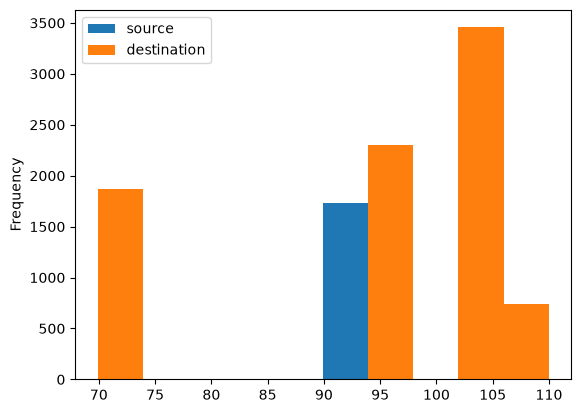

In [63]:
location_p1.fit_transform(x_train[['source', 'destination']], y_train).plot(kind='hist')

In [34]:
x_train.columns.to_list()

['airline',
 'date_of_journey',
 'source',
 'destination',
 'dep_time',
 'arrival_time',
 'duration',
 'total_stops',
 'additional_info']

In [38]:
np.union1d(x_train.source.unique(), x_train.destination.unique())

array(['Banglore', 'Chennai', 'Cochin', 'Delhi', 'Hyderabad', 'Kolkata',
       'Mumbai', 'New Delhi'], dtype=object)

In [70]:
def is_north(df):

    col = df.columns.to_list()
    north_cities = ['Delhi', 'New Delhi', 'Kolkata', 'Mumbai']

    return (df.assign(
        **{
            f'{i}_is_north' : df.loc[:, i].isin(north_cities).astype(int) for i in col
        }
    )
    .drop(columns=col))

FunctionTransformer(func=is_north).fit_transform(x_train[['source', 'destination']])

,source_is_north,destination_is_north
0,1,0
1,0,1
2,1,0
3,1,0
4,1,0
...,...,...
8364,1,0
8365,0,1
8366,1,0
8367,0,1


In [67]:
source_destination_transformer = FeatureUnion([
    ('Pipe1', location_p1),
    ('Pipe2', FunctionTransformer(func=is_north))
])

In [71]:
source_destination_transformer.fit_transform(x_train[['source', 'destination']], y_train)

,Pipe1__source,Pipe1__destination,Pipe2__source_is_north,Pipe2__destination_is_north
0,102.279119,102.279119,1,0
1,90.067110,71.739090,0,1
2,70.845211,70.845211,1,0
3,95.756808,95.756808,1,0
4,102.279119,102.279119,1,0
...,...,...,...,...
8364,95.756808,95.756808,1,0
8365,90.067110,71.739090,0,1
8366,102.279119,102.279119,1,0
8367,90.067110,71.739090,0,1


### Departure Time and Arrival Time 

In [72]:
x_train[['dep_time', 'arrival_time']]

,dep_time,arrival_time
0,11:40:00,19:00:00
1,15:15:00,18:10:00
2,13:55:00,15:25:00
3,14:05:00,19:50:00
4,08:45:00,13:15:00
...,...,...
8364,18:55:00,12:00:00
8365,17:00:00,19:35:00
8366,12:50:00,01:30:00
8367,07:45:00,10:40:00


In [73]:
time_p1 = Pipeline(steps=[
    # extracting hour and min
    ('dt', DatetimeFeatures(features_to_extract=['hour', 'minute'], missing_values='ignore')),
    # scaling 
    ('scaler', MinMaxScaler())
])

In [74]:
time_p1.fit_transform(x_train[['dep_time', 'arrival_time']])

,dep_time_hour,dep_time_minute,arrival_time_hour,arrival_time_minute
0,0.478261,0.727273,0.826087,0.000000
1,0.652174,0.272727,0.782609,0.181818
2,0.565217,1.000000,0.652174,0.454545
3,0.608696,0.090909,0.826087,0.909091
4,0.347826,0.818182,0.565217,0.272727
...,...,...,...,...
8364,0.782609,1.000000,0.521739,0.000000
8365,0.739130,0.000000,0.826087,0.636364
8366,0.521739,0.909091,0.043478,0.545455
8367,0.304348,0.818182,0.434783,0.727273


In [203]:
def time_period(df):

    def helper(data):
        
        data = pd.to_datetime(data).hour
        if 5<= data < 12:
            return 'morning'
        elif 12 <= data < 18:
            return 'afternoon'
        elif 18<= data <21:
            return 'evening'
        else:
            return 'night'

            
    col = df.columns.to_list()

    return (
        df.assign(
            **{
                f'{i}_period': df.loc[:, i].apply(helper) for i in col
            }
        )
        .drop(columns=col)
    )

In [204]:
time_period(df[['dep_time', 'arrival_time']])

,dep_time_period,arrival_time_period
0,morning,evening
1,afternoon,evening
2,afternoon,afternoon
3,afternoon,evening
4,morning,afternoon
...,...,...
8364,evening,afternoon
8365,afternoon,evening
8366,afternoon,night
8367,morning,morning


In [228]:
time_p2 = Pipeline(steps=[
    # passing time_period function
    ('period', FunctionTransformer(func=time_period, feature_names_out=lambda transformer, input_features: [
        f'{col}_period' for col in input_features
    ])),
    # CountFrequencty encoder 
    ('encoder', CountFrequencyEncoder()),
    # scaling
    ('scaler', MinMaxScaler())
])
time_p2.fit_transform(df[['dep_time', 'arrival_time']])

,dep_time_period,arrival_time_period
0,1.000000,0.140511
1,0.320403,0.140511
2,0.320403,0.000000
3,0.320403,0.140511
4,1.000000,0.000000
...,...,...
8364,0.054084,0.000000
8365,0.320403,0.140511
8366,0.320403,1.000000
8367,1.000000,0.042883


In [229]:
dep_arrival_time_tranformer = FeatureUnion([
    ('part1', time_p1),
    ('part2', time_p2)
])

dep_arrival_time_tranformer.fit_transform(df[['dep_time', 'arrival_time']])

,part1__dep_time_hour,part1__dep_time_minute,part1__arrival_time_hour,part1__arrival_time_minute,part2__dep_time_period,part2__arrival_time_period
0,0.478261,0.727273,0.826087,0.000000,1.000000,0.140511
1,0.652174,0.272727,0.782609,0.181818,0.320403,0.140511
2,0.565217,1.000000,0.652174,0.454545,0.320403,0.000000
3,0.608696,0.090909,0.826087,0.909091,0.320403,0.140511
4,0.347826,0.818182,0.565217,0.272727,1.000000,0.000000
...,...,...,...,...,...,...
8364,0.782609,1.000000,0.521739,0.000000,0.054084,0.000000
8365,0.739130,0.000000,0.826087,0.636364,0.320403,0.140511
8366,0.521739,0.909091,0.043478,0.545455,0.320403,1.000000
8367,0.304348,0.818182,0.434783,0.727273,1.000000,0.042883


### Duration

In [117]:
x_train.duration

0        440
1        175
2         90
3        345
4        270
        ... 
8364    1025
8365     155
8366     760
8367     175
8368     570
Name: duration, Length: 8369, dtype: int64

In [230]:
def duration_cat(df):

    bins = [0, 180, 360, 700, float('inf')]

    labels = ['short', 'medium', 'long', 'very long']
    
    return pd.cut(
        df['duration'],
        bins=bins,
        labels=labels
    ).rename('duration_category').to_frame()
    
duration_cat(x_train[['duration']])

,duration_category
0,long
1,short
2,short
3,medium
4,medium
...,...
8364,very long
8365,short
8366,very long
8367,short


In [232]:
duration_transformer = FeatureUnion([
    
    ('cat', Pipeline(steps=[
        # appling duration_cat function 
        ('dur_cat', FunctionTransformer(func=duration_cat, feature_names_out=lambda transformer, input_features: [
        'duration_category'
    ])),
        # label encoding
        ('encoder', OrdinalEncoder(categories=[['short', 'medium', 'long', 'very long']]))
        ])
    ),

    ('encoder', StandardScaler())
])

duration_transformer.fit_transform(x_train[['duration']])

,cat__duration_category,encoder__duration
0,2.0,-0.376936
1,0.0,-0.906354
2,0.0,-1.076168
3,1.0,-0.566728
4,1.0,-0.716563
...,...,...
8364,3.0,0.791779
8365,0.0,-0.946310
8366,3.0,0.262361
8367,0.0,-0.906354


### Total Stops

In [146]:
x_train.total_stops

0       1
1       0
2       0
3       1
4       1
       ..
8364    1
8365    0
8366    1
8367    0
8368    1
Name: total_stops, Length: 8369, dtype: int64

In [224]:
def is_direct_flight(df):
    return df.total_stops.eq(0).astype(int).to_frame()

In [235]:
stops_tansformer = Pipeline(steps=[
    # filling nan values with most_frequent
    ('imputer', SimpleImputer(strategy='most_frequent')),
    # applying is direct flight function 
    ('direct', FunctionTransformer(func=is_direct_flight, feature_names_out=lambda transformer, input_features: [
        'total_stops'
    ]))
])
stops_tansformer.fit_transform(x_train[['total_stops']])

,total_stops
0,0
1,1
2,1
3,0
4,0
...,...
8364,0
8365,1
8366,0
8367,1


### Additional Info

In [159]:
x_train.additional_info.unique()

<StringArray>
[                     'No Info',  'In-Flight Meal Not Included',
 'No Check-In Baggage Included',               '2 Long Layover',
              'Change Airports',               '1 Long Layover',
               'Red-Eye Flight',              '1 Short Layover',
               'Business Class']
Length: 9, dtype: str

In [178]:
def have_info(df):
    return df.additional_info.eq('No Info').astype(int).to_frame()

have_info(x_train[['additional_info']])

,additional_info
0,1
1,0
2,1
3,0
4,0
...,...
8364,0
8365,1
8366,1
8367,1


In [179]:
info_transformer = FeatureUnion([
    ('pipe1', Pipeline(steps=[
        # handling missing values 
        ('imputer', SimpleImputer(strategy='most_frequent')),
        # grouping less than 10% categoris to others
        ('grouper', RareLabelEncoder(tol=0.1, n_categories=2, replace_with='other')),
        # oneHot Encoding
        ('ohe', OneHotEncoder(sparse_output=False, handle_unknown='ignore'))    
        ])
    ),

    ('have_info', FunctionTransformer(func=have_info))
])

info_transformer.fit_transform(x_train[['additional_info']])

,pipe1__additional_info_In-Flight Meal Not Included,pipe1__additional_info_No Info,pipe1__additional_info_other,have_info__additional_info
0,0.0,1.0,0.0,1
1,1.0,0.0,0.0,0
2,0.0,1.0,0.0,1
3,1.0,0.0,0.0,0
4,0.0,0.0,1.0,0
...,...,...,...,...
8364,1.0,0.0,0.0,0
8365,0.0,1.0,0.0,1
8366,0.0,1.0,0.0,1
8367,0.0,1.0,0.0,1


### Column Tranformer

In [184]:
x_train.sample()

,airline,date_of_journey,source,destination,dep_time,arrival_time,duration,total_stops,additional_info
5564,Jet Airways,2019-05-18,Kolkata,Banglore,16:30:00,04:40:00,730,1,No Info


In [236]:
col_transformer = ColumnTransformer(transformers=[
    
    ('airline', airline_transformer, ['airline']),
    ('doj', doj_transformer, ['date_of_journey']),
    ('location', source_destination_transformer, ['source', 'destination']),
    ('time', dep_arrival_time_tranformer, ['dep_time', 'arrival_time']),
    ('duration', duration_transformer, ['duration']),
    ('stops', stops_tansformer, ['total_stops']),
    ('info', info_transformer, ['additional_info'])
    
])

col_transformer.fit_transform(x_train, y_train)

,airline__airline_Air India,airline__airline_Indigo,airline__airline_Jet Airways,airline__airline_Multiple Carriers,airline__airline_Spicejet,airline__airline_other,doj__date_of_journey_month,doj__date_of_journey_week,doj__date_of_journey_day_of_week,doj__date_of_journey_day_of_month,doj__date_of_journey_day_of_year,location__Pipe1__source,location__Pipe1__destination,location__Pipe2__source_is_north,location__Pipe2__destination_is_north,time__part1__dep_time_hour,time__part1__dep_time_minute,time__part1__arrival_time_hour,time__part1__arrival_time_minute,time__part2__dep_time_period,time__part2__arrival_time_period,duration__cat__duration_category,duration__encoder__duration,stops__total_stops,info__pipe1__additional_info_In-Flight Meal Not Included,info__pipe1__additional_info_No Info,info__pipe1__additional_info_other,info__have_info__additional_info
0,0.0,0.0,0.0,1.0,0.0,0.0,0.666667,0.764706,0.000000,1.000000,0.737288,102.279119,102.279119,1,0,0.478261,0.727273,0.826087,0.000000,1.000000,0.140511,2.0,-0.376936,0,0.0,1.0,0.0,1
1,0.0,0.0,1.0,0.0,0.0,0.0,1.000000,0.823529,1.000000,0.307692,0.847458,90.067110,71.739090,0,1,0.652174,0.272727,0.782609,0.181818,0.320403,0.140511,0.0,-0.906354,1,1.0,0.0,0.0,0
2,1.0,0.0,0.0,0.0,0.0,0.0,0.666667,0.705882,0.666667,0.884615,0.711864,70.845211,70.845211,1,0,0.565217,1.000000,0.652174,0.454545,0.320403,0.000000,0.0,-1.076168,1,0.0,1.0,0.0,1
3,0.0,0.0,1.0,0.0,0.0,0.0,0.666667,0.705882,0.666667,0.884615,0.711864,95.756808,95.756808,1,0,0.608696,0.090909,0.826087,0.909091,0.320403,0.140511,1.0,-0.566728,0,1.0,0.0,0.0,0
4,0.0,0.0,0.0,0.0,1.0,0.0,0.666667,0.705882,0.166667,0.769231,0.686441,102.279119,102.279119,1,0,0.347826,0.818182,0.565217,0.272727,1.000000,0.000000,1.0,-0.716563,0,0.0,0.0,1.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8364,0.0,0.0,1.0,0.0,0.0,0.0,0.000000,0.176471,1.000000,0.884615,0.194915,95.756808,95.756808,1,0,0.782609,1.000000,0.521739,0.000000,0.054084,0.000000,3.0,0.791779,0,1.0,0.0,0.0,0
8365,0.0,0.0,0.0,0.0,0.0,1.0,0.666667,0.588235,0.500000,0.307692,0.584746,90.067110,71.739090,0,1,0.739130,0.000000,0.826087,0.636364,0.320403,0.140511,0.0,-0.946310,1,0.0,1.0,0.0,1
8366,0.0,0.0,0.0,1.0,0.0,0.0,0.666667,0.588235,0.500000,0.307692,0.584746,102.279119,102.279119,1,0,0.521739,0.909091,0.043478,0.545455,0.320403,1.000000,3.0,0.262361,0,0.0,1.0,0.0,1
8367,0.0,0.0,0.0,0.0,0.0,1.0,0.666667,0.647059,0.333333,0.538462,0.635593,90.067110,71.739090,0,1,0.304348,0.818182,0.434783,0.727273,1.000000,0.042883,0.0,-0.906354,1,0.0,1.0,0.0,1


## Feature Selection

In [239]:
model = RandomForestRegressor(max_depth=4, random_state=149,n_jobs=-1)

In [240]:
selector = SelectBySingleFeaturePerformance(model, scoring='r2', cv=5, threshold=0.1)

In [241]:
selection = Pipeline(steps=[
    ('col_transformer', col_transformer),
    ('selector', selector)
])
selection.fit_transform(x_train, y_train)

,airline__airline_Indigo,airline__airline_Jet Airways,doj__date_of_journey_week,doj__date_of_journey_day_of_year,location__Pipe1__source,location__Pipe1__destination,time__part1__arrival_time_hour,duration__cat__duration_category,duration__encoder__duration,stops__total_stops
0,0.0,0.0,0.764706,0.737288,102.279119,102.279119,0.826087,2.0,-0.376936,0
1,0.0,1.0,0.823529,0.847458,90.067110,71.739090,0.782609,0.0,-0.906354,1
2,0.0,0.0,0.705882,0.711864,70.845211,70.845211,0.652174,0.0,-1.076168,1
3,0.0,1.0,0.705882,0.711864,95.756808,95.756808,0.826087,1.0,-0.566728,0
4,0.0,0.0,0.705882,0.686441,102.279119,102.279119,0.565217,1.0,-0.716563,0
...,...,...,...,...,...,...,...,...,...,...
8364,0.0,1.0,0.176471,0.194915,95.756808,95.756808,0.521739,3.0,0.791779,0
8365,0.0,0.0,0.588235,0.584746,90.067110,71.739090,0.826087,0.0,-0.946310,1
8366,0.0,0.0,0.588235,0.584746,102.279119,102.279119,0.043478,3.0,0.262361,0
8367,0.0,0.0,0.647059,0.635593,90.067110,71.739090,0.434783,0.0,-0.906354,1
